Question 66. Construct and visualise a minimum spanning tree using city distances based on latitude/longitude.

Original dataset:


,OID,Date,City,Region,Age,Category,Sales,Profit,Latitude,Longitude
0,O01,2026-01-01,Delhi,North,25,Grocery,1500,200,28.61,77.23
1,O02,2026-01-03,Mumbai,West,32,Electronics,12000,1500,19.07,72.87
2,O03,2026-01-05,Chennai,South,28,Clothing,3500,500,13.08,80.27
3,O04,2026-01-07,Kolkata,East,40,Grocery,2000,250,22.57,88.36
4,O05,2026-01-09,Bangalore,South,35,Electronics,15000,2000,12.97,77.59
5,O06,2026-01-11,Jaipur,North,29,Clothing,4000,600,26.91,75.79
6,O07,2026-01-13,Pune,West,31,Grocery,1800,300,18.52,73.85
7,O08,2026-01-15,Hyderabad,South,27,Electronics,11000,1300,17.38,78.48
8,O09,2026-01-17,Ahmedabad,West,45,Clothing,5000,700,23.02,72.57
9,O10,2026-01-19,Lucknow,North,38,Grocery,2200,350,26.85,80.95


,City1,City2,Distance_km
0,Delhi,Jaipur,236.234334
1,Delhi,Lucknow,415.123770
2,Mumbai,Pune,119.925713
3,Mumbai,Ahmedabad,440.321978
4,Chennai,Bangalore,290.591883
5,Kolkata,Lucknow,886.679034
6,Bangalore,Hyderabad,499.580050
7,Jaipur,Ahmedabad,540.729295
8,Pune,Hyderabad,505.889907


Total MST distance: 3935.08 km


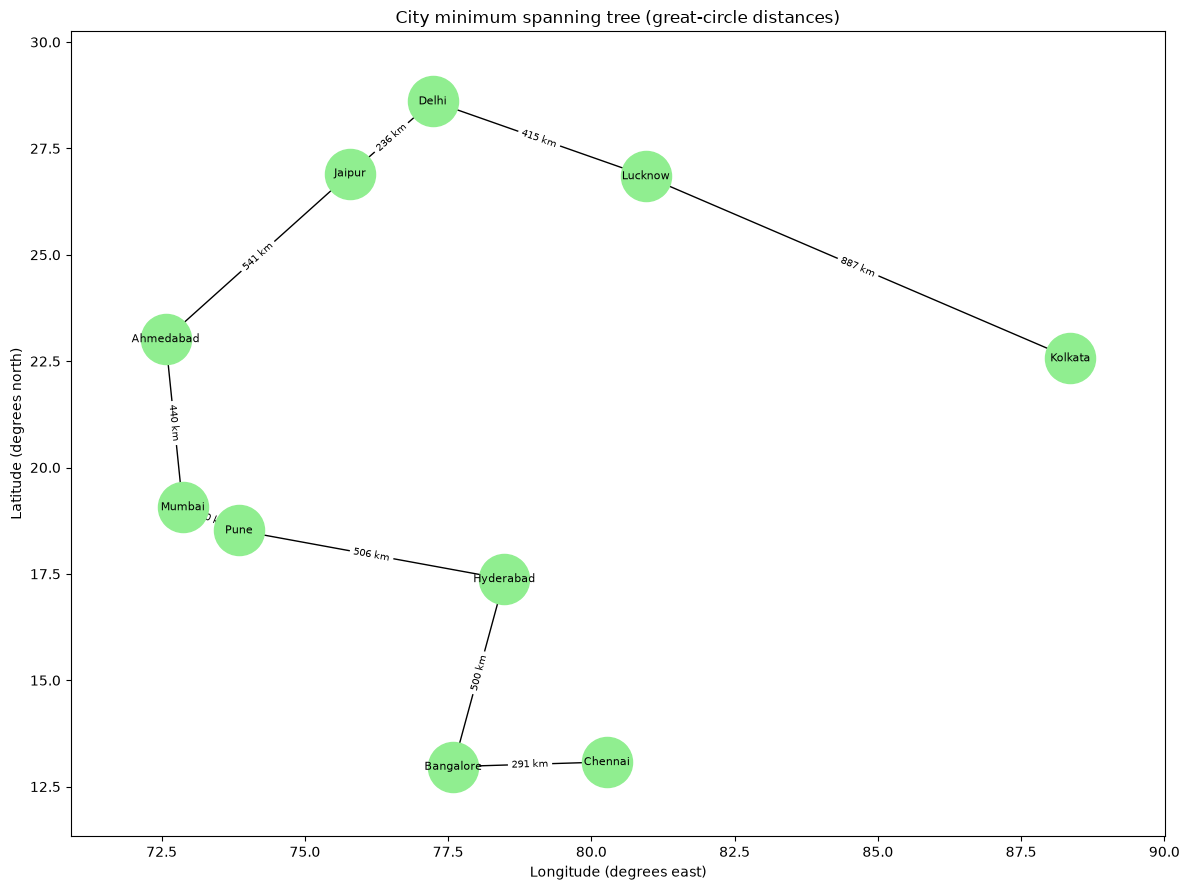

Saved question66_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import networkx as nx

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_SalesData.csv")
print("Original dataset:")
display(df)

# Step 3: Extract the city coordinates and create a graph containing all cities.
cities = df[["City", "Latitude", "Longitude"]].drop_duplicates("City").set_index("City")
graph = nx.Graph()
graph.add_nodes_from(cities.index)

# Step 4: Calculate great-circle distances for every city pair with the Haversine formula.
for i, city1 in enumerate(cities.index):
    lat1, lon1 = np.radians(cities.loc[city1, ["Latitude", "Longitude"]].to_numpy(dtype=float))
    for city2 in cities.index[i + 1:]:
        lat2, lon2 = np.radians(cities.loc[city2, ["Latitude", "Longitude"]].to_numpy(dtype=float))
        a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
        distance = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        graph.add_edge(city1, city2, weight=float(distance))

# Step 5: Keep the links connecting all cities with the smallest possible total distance.
mst = nx.minimum_spanning_tree(graph, weight="weight")

# Step 6: Use actual longitude/latitude coordinates to draw the spanning tree.
positions = {city: (row.Longitude, row.Latitude) for city, row in cities.iterrows()}
fig, ax = plt.subplots(figsize=(12, 9))
nx.draw_networkx(mst, positions, ax=ax, node_color="lightgreen", node_size=1300, font_size=8)
nx.draw_networkx_edge_labels(mst, positions, ax=ax,
    edge_labels={(u, v): f"{data['weight']:.0f} km" for u, v, data in mst.edges(data=True)}, font_size=7)
ax.set(xlabel="Longitude (degrees east)", ylabel="Latitude (degrees north)",
       title="City minimum spanning tree (great-circle distances)")
ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

# Step 7: Display and save distances for the selected links.
edges = pd.DataFrame([(u, v, d["weight"]) for u, v, d in mst.edges(data=True)],
                     columns=["City1", "City2", "Distance_km"])
display(edges)
print(f"Total MST distance: {edges['Distance_km'].sum():.2f} km")
edges.to_csv("minimum_spanning_tree.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question66_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question66_plot.png")


Interpretation / method

Haversine great-circle distances in kilometres are used, not Euclidean distances in degrees or road distances. A spanning tree of ten cities has nine edges.